In [112]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

In [113]:
no_person_img = plt.imread('no_person_crop.png')
type(no_person_img), no_person_img.shape, no_person_img.dtype

(numpy.ndarray, (80, 80, 4), dtype('float32'))

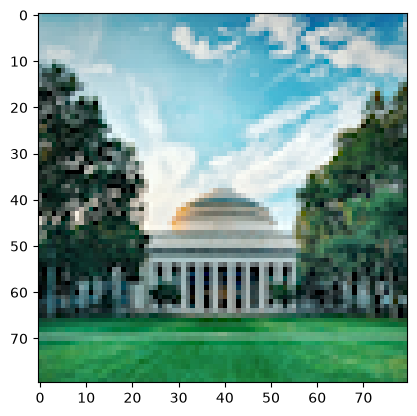

In [114]:
plt.imshow(no_person_img)

In [115]:
no_person_img = no_person_img[:, :, :3]

In [116]:
temp_first_row = no_person_img[0, :, :]
temp_first_row

array([[0.4862745 , 0.6901961 , 0.7372549 ],
       [0.4       , 0.6745098 , 0.7254902 ],
       [0.39607844, 0.67058825, 0.7294118 ],
       [0.39215687, 0.6627451 , 0.7254902 ],
       [0.39607844, 0.65882355, 0.72156864],
       [0.3764706 , 0.65882355, 0.7176471 ],
       [0.38039216, 0.654902  , 0.7176471 ],
       [0.4       , 0.65882355, 0.72156864],
       [0.40392157, 0.654902  , 0.7176471 ],
       [0.4509804 , 0.67058825, 0.72156864],
       [0.47058824, 0.68235296, 0.7294118 ],
       [0.4627451 , 0.6745098 , 0.72156864],
       [0.4862745 , 0.6784314 , 0.7254902 ],
       [0.50980395, 0.69411767, 0.7411765 ],
       [0.4745098 , 0.6862745 , 0.73333335],
       [0.42745098, 0.6627451 , 0.7254902 ],
       [0.39215687, 0.64705884, 0.72156864],
       [0.3882353 , 0.6431373 , 0.7176471 ],
       [0.35686275, 0.6431373 , 0.7137255 ],
       [0.3647059 , 0.6431373 , 0.72156864],
       [0.35686275, 0.6431373 , 0.72156864],
       [0.32156864, 0.6392157 , 0.72156864],
       [0.

In [117]:
(temp_first_row* 255) - 128

array([[  -4.,   48.,   60.],
       [ -26.,   44.,   57.],
       [ -27.,   43.,   58.],
       [ -28.,   41.,   57.],
       [ -27.,   40.,   56.],
       [ -32.,   40.,   55.],
       [ -31.,   39.,   55.],
       [ -26.,   40.,   56.],
       [ -25.,   39.,   55.],
       [ -13.,   43.,   56.],
       [  -8.,   46.,   58.],
       [ -10.,   44.,   56.],
       [  -4.,   45.,   57.],
       [   2.,   49.,   61.],
       [  -7.,   47.,   59.],
       [ -19.,   41.,   57.],
       [ -28.,   37.,   56.],
       [ -29.,   36.,   55.],
       [ -37.,   36.,   54.],
       [ -35.,   36.,   56.],
       [ -37.,   36.,   56.],
       [ -46.,   35.,   56.],
       [ -48.,   35.,   57.],
       [ -48.,   35.,   57.],
       [ -46.,   35.,   57.],
       [ -43.,   35.,   57.],
       [ -34.,   36.,   57.],
       [ -33.,   35.,   57.],
       [ -42.,   33.,   55.],
       [ -55.,   29.,   52.],
       [ -59.,   26.,   51.],
       [ -63.,   22.,   49.],
       [ -69.,   18.,   47.],
       [ -

### Trying export my passport for model testing

In [118]:
matthew_image = Image.open("matthew_passport.jpg")

In [119]:
matthew_image_resize = matthew_image.resize((no_person_img.shape[1], no_person_img.shape[0]))
matthew_image_resize.show()

In [120]:
matthew_image_array = np.array(matthew_image_resize)
matthew_image_array.shape, matthew_image_array.dtype, matthew_image_array.min(), matthew_image_array.max()

((80, 80, 3), dtype('uint8'), np.uint8(8), np.uint8(255))

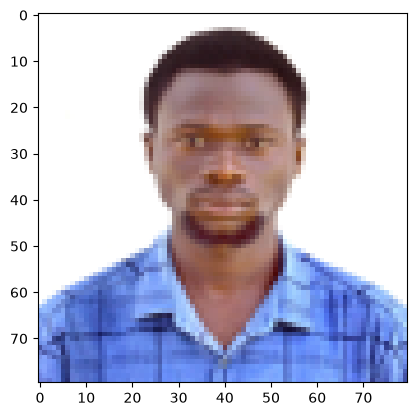

In [121]:
plt.imshow(matthew_image_array)

In [122]:

def np_to_c_array(arr, name="my_array"):
    """Generates a C string declaration for a multi-dimensional NumPy array."""

    def format_rec(sub_arr):
        if sub_arr.ndim == 1:
            return "{" + ", ".join(map(str, sub_arr)) + "}"
        return "{\n" + ",\n".join(format_rec(x) for x in sub_arr) + "\n}"

    # Map numpy types to basic C types
    c_type = "double" if "float" in str(arr.dtype) else "int"
    dimensions = "".join(f"[{dim}]" for dim in arr.shape)

    return f"const {c_type} {name}{dimensions} = {format_rec(arr)};"

In [123]:
matthew_image_array.max(), matthew_image_array.min(), matthew_image_array.mean(), matthew_image_array.std()

(np.uint8(255),
 np.uint8(8),
 np.float64(187.74125),
 np.float64(74.22699928892115))

In [124]:
matthew_image_array_reduced = matthew_image_array.flatten().astype(np.int16) - 128

matthew_image_array_reduced.max(), matthew_image_array_reduced.min()

(np.int16(127), np.int16(-120))

In [125]:
matthew_image_array_str = np_to_c_array(matthew_image_array_reduced, "matthew_image_array")
with open("matthew_image_array.h", "w") as f:
    f.write(matthew_image_array_str)
matthew_image_array_str

'const int matthew_image_array[19200] = {127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127, 127,